# 📊 Comprehensive Exploratory Data Analysis (EDA) & Relational Profiling
## CreditNirvana Collections, Spatial Geocoding & Telephony Dataset
---
### 📌 Executive Summary
This notebook delivers a thorough, granular **Exploratory Data Analysis (EDA)** across all dataset tables in the CreditNirvana ecosystem. 
The datasets span three core problem domains:
1. **Shared Core Tables**: Loan accounts, borrower KYC addresses, field visits, dial attempts, payments, agents, lenders, and data splits.
2. **Problem Statement 3 (Geocoding_Engine - Spatial Geocoder)**: Commercial baseline geocodes, field visit GPS breadcrumb trails, surveyed ground-truth coordinates, town geographies, locality centroids, and landmark POIs.
3. **Problem Statement 1 (PS1 - Fake PTP Detection)**: Promises to Pay (PTPs), turn-by-turn call audio transcripts, post-call engagement events, and expert annotations.
4. **Problem Statement 2 (PS2 - Right-Party Contact)**: Phone inventory, skip-trace vendor queries, and phone verification campaigns.

### 🎯 Key Focus Areas of this Notebook:
- **Exhaustive Dataset Inventory**: Row counts, dimensions, file footprints, and data types across all 21 CSVs.
- **Data Quality & Missingness**: Granular null-value distribution and domain rationale for sparse fields.
- **Uniqueness & Primary Key Verification**: Complete cardinality profiling (`nunique`, unique ratios, candidate keys).
- **Relational Relevancy & Cross-Table Linkage**: Intersections, foreign-key overlap matrices, Jaccard similarity, and borrower journey funnels.
- **Spatial & Geocoding Deep-Dive**: Error quantification of commercial geocoders against ground-truth surveyed locations, GPS accuracy, and check-in power.
- **Fraud & Anomaly Screening**: Photo-hash duplication detection (agent spoofing) and GPS teleportation identification.
- **Multivariate Correlation & Modeling Recommendations**: Feature relationships and practical data science strategies.

In [ ]:
import os
import glob
import re
import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14

# Define base paths
BASE_DIR = os.path.abspath(r'c:\Users\kmzpa\Desktop\Open IIT Data\Dataset\data')
SHARED_DIR = os.path.join(BASE_DIR, 'shared')
Geocoding_Engine_DIR = os.path.join(BASE_DIR, 'address_geocoder')
PS1_DIR = os.path.join(BASE_DIR, 'ps1_fake_ptp')
PS2_DIR = os.path.join(BASE_DIR, 'ps2_right_party_contact')

print(f"Data root directory: {BASE_DIR}")
print("Subdirectories verified:")
for p in [SHARED_DIR, Geocoding_Engine_DIR, PS1_DIR, PS2_DIR]:
    print(f"  - {os.path.basename(p)}: {'[OK]' if os.path.exists(p) else '[MISSING]'}")

Data root directory: c:\Users\kmzpa\Desktop\Open IIT Data\Dataset\data
Subdirectories verified:
  - shared: [MISSING]
  - address_geocoder: [MISSING]
  - ps1_fake_ptp: [MISSING]
  - ps2_right_party_contact: [MISSING]


## 1. 📂 Master Dataset Catalog & Volume Profiling
In this section, we scan the entire dataset directory to build a unified catalog table detailing:
- Dataset name & category
- Row count & column count
- Disk file size & in-memory DataFrame memory footprint
- Primary Key candidates and target problem statements

In [ ]:
# Scan and catalog all CSV files
catalog_records = []
dataframes = {}

for folder, domain in [(SHARED_DIR, 'Shared'), (Geocoding_Engine_DIR, 'Geocoding_Engine: Geocoder'), 
                       (PS1_DIR, 'PS1: Fake PTP'), (PS2_DIR, 'PS2: RPC')]:
    for f in sorted(os.listdir(folder)):
        if f.endswith('.csv'):
            fpath = os.path.join(folder, f)
            size_kb = os.path.getsize(fpath) / 1024
            df = pd.read_csv(fpath)
            dataframes[f] = df
            mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
            catalog_records.append({
                'Domain': domain,
                'File Name': f,
                'Rows': len(df),
                'Columns': len(df.columns),
                'File Size (KB)': round(size_kb, 1),
                'RAM Memory (MB)': round(mem_mb, 2),
                'Primary Key (Candidate)': df.columns[0] if len(df.columns) > 0 else 'N/A'
            })

catalog_df = pd.DataFrame(catalog_records).sort_values(by='Rows', ascending=False).reset_index(drop=True)
print("=== COMPLETE DATASET INVENTORY (21 TABLES) ===")
print(catalog_df.to_string(index=False))

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 8, in <module>
FileNotFoundError: [WinError 3] The system cannot find the path specified: 'c:\\Users\\kmzpa\\Desktop\\Open IIT Data\\Dataset\\data\\shared'


### 📊 Visualizing Dataset Scale & Storage Footprint
The tables vary dramatically in scale, from reference configuration tables (`towns.csv` with 3 rows, `lenders.csv` with 6 rows) to high-frequency event streams (`visit_gps_points.csv` with 160,406 points and `dial_attempts.csv` with 51,105 records).

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 6, in <module>
NameError: name 'catalog_df' is not defined


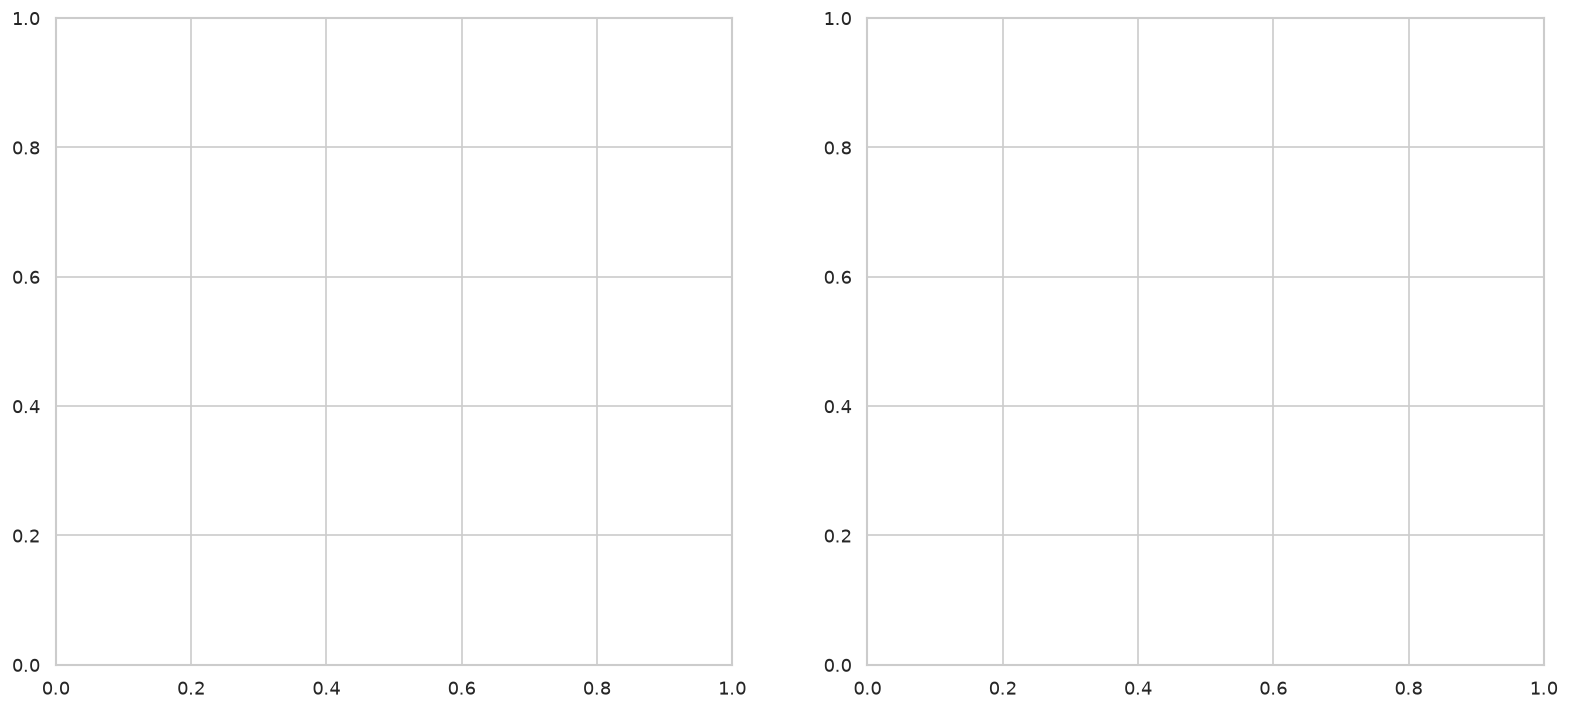

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Row counts comparison (log scale)
sns.barplot(
    data=catalog_df, 
    y='File Name', 
    x='Rows', 
    hue='Domain', 
    dodge=False, 
    ax=axes[0], 
    palette='Set2'
)
axes[0].set_xscale('log')
axes[0].set_title('Dataset Row Counts (Logarithmic Scale)', pad=12)
axes[0].set_xlabel('Number of Rows (log10)')
axes[0].set_ylabel('Dataset File')
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# Annotate row counts
for i, row in catalog_df.iterrows():
    axes[0].text(row['Rows'] * 1.15, i, f"{row['Rows']:,}", va='center', fontsize=8, color='#333333')

# 2. Disk file size comparison (KB)
sns.barplot(
    data=catalog_df, 
    y='File Name', 
    x='File Size (KB)', 
    hue='Domain', 
    dodge=False, 
    ax=axes[1], 
    palette='Set2'
)
axes[1].set_title('Disk Storage Footprint (KB)', pad=12)
axes[1].set_xlabel('File Size (KB)')
axes[1].set_ylabel('')
axes[1].grid(True, ls="--", alpha=0.5)

# Annotate file sizes
for i, row in catalog_df.iterrows():
    axes[1].text(row['File Size (KB)'] + 50, i, f"{row['File Size (KB)']:.0f} KB", va='center', fontsize=8, color='#333333')

plt.tight_layout()
plt.show()

## 2. 🔍 Missing Values & Data Quality Audit
High-quality machine learning and statistical modeling require knowing precisely which features contain missing values, their frequency, and their structural business cause.

In [ ]:
# Collect missing value metrics across all tables
null_summary = []

for fname, df in dataframes.items():
    total_rows = len(df)
    null_cols = df.isnull().sum()
    null_cols = null_cols[null_cols > 0]
    for col, n_missing in null_cols.items():
        pct = (n_missing / total_rows) * 100
        null_summary.append({
            'File': fname,
            'Column': col,
            'Missing Rows': n_missing,
            'Total Rows': total_rows,
            'Missing Rate (%)': round(pct, 2)
        })

null_df = pd.DataFrame(null_summary).sort_values(by='Missing Rate (%)', ascending=False).reset_index(drop=True)

print("=== COLUMNS WITH MISSING VALUES ===")
if len(null_df) > 0:
    print(null_df.to_string(index=False))
else:
    print("No missing values found across any table!")

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 19, in <module>
  File "C:\Users\kmzpa\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\site-packages\pandas\core\frame.py", line 8361, in sort_values
    k = self._get_label_or_level_values(by[0], axis=axis)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\kmzpa\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\site-packages\pandas\core\generic.py", line 1764, in _get_label_or_level_values
    raise KeyError(key)
KeyError: 'Missing Rate (%)'


### 📉 Visualizing Missingness Rates & Structural Patterns
The missingness observed across the tables is predominantly **Missing Structurally by Design**:
- `ptp_id` in `dial_attempts.csv` (93.9% missing): Call attempts only generate a PTP when an agreement is reached with the borrower.
- `salary_credit_day` in `accounts.csv` (68.3% missing): Only salaried borrowers have salary credit dates; self-employed borrowers do not.
- `new_contact_point_id` in `skip_traces.csv` (77.2% missing): Populated only when the skip-trace provider successfully discovers a new contact.
- `ptp_id` in `field_visits.csv` (89.2% missing): Field visits only capture PTPs when borrower or family member agrees to pay.

In [ ]:
if len(null_df) > 0:
    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        data=null_df, 
        x='Missing Rate (%)', 
        y='Column', 
        hue='File', 
        dodge=False, 
        palette='rocket'
    )
    plt.title('Missing Value Percentage by Column & Originating Table', pad=14)
    plt.xlabel('Missing Percentage (%)')
    plt.ylabel('Attribute Name')
    plt.xlim(0, 105)
    
    # Annotate bars
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f"{width:.1f}%", (width + 1.2, p.get_y() + p.get_height() / 2.),
                        va='center', fontsize=9, fontweight='bold', color='#222222')
            
    plt.grid(True, ls="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
NameError: name 'null_df' is not defined


## 3. 🔑 Uniqueness, Primary Keys & Cardinality Profiling
A deep dive into column uniqueness (`nunique`), uniqueness ratio ($rac{\text{nunique}}{N}$), and column cardinality classification:
- **Primary Key Candidates**: Uniqueness ratio $= 1.0$ (100% unique, zero duplicates).
- **High Cardinality Identifiers**: Uniqueness ratio $> 0.5$ (frequent identifiers, unique measurements).
- **Categorical / Low Cardinality**: Attributes with distinct category states (channels, outcomes, status, buckets).
- **Binary Flags**: Exactly 2 unique states (booleans, binary indicators).

In [ ]:
# Exhaustive Uniqueness Profiling
uniqueness_records = []

for fname, df in dataframes.items():
    n_rows = len(df)
    for col in df.columns:
        n_unq = df[col].nunique()
        n_null = df[col].isnull().sum()
        unq_ratio = n_unq / n_rows if n_rows > 0 else 0
        
        # Determine classification
        if unq_ratio == 1.0 and n_null == 0:
            cardinality_type = 'Primary Key (100% Unique)'
        elif unq_ratio >= 0.5:
            cardinality_type = 'High Cardinality Identifier'
        elif n_unq == 2:
            cardinality_type = 'Binary Flag'
        elif n_unq <= 15:
            cardinality_type = 'Low Cardinality Categorical'
        else:
            cardinality_type = 'Medium Cardinality Numeric/Categorical'
            
        uniqueness_records.append({
            'Table': fname,
            'Column': col,
            'Data Type': str(df[col].dtype),
            'Distinct Count': n_unq,
            'Total Rows': n_rows,
            'Uniqueness Ratio': round(unq_ratio, 4),
            'Classification': cardinality_type
        })

uniqueness_df = pd.DataFrame(uniqueness_records)

print(f"Total columns analyzed across all 21 tables: {len(uniqueness_df)}")
print("
Breakdown of Column Classifications:")
print(uniqueness_df['Classification'].value_counts())

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 37
    print("
          ^
SyntaxError: unterminated string literal (detected at line 37)


### 📋 Verified Primary Keys & High-Cardinality Entities Across Tables
Let's inspect the verified unique primary keys across every dataset:

In [ ]:
# Filter candidate primary keys
pk_df = uniqueness_df[uniqueness_df['Classification'] == 'Primary Key (100% Unique)'][['Table', 'Column', 'Distinct Count', 'Data Type']].reset_index(drop=True)
print("=== VERIFIED PRIMARY KEY COLUMNS ===")
print(pk_df.to_string(index=False))

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 3, in <module>
NameError: name 'uniqueness_df' is not defined


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 4, in <module>
NameError: name 'uniqueness_df' is not defined


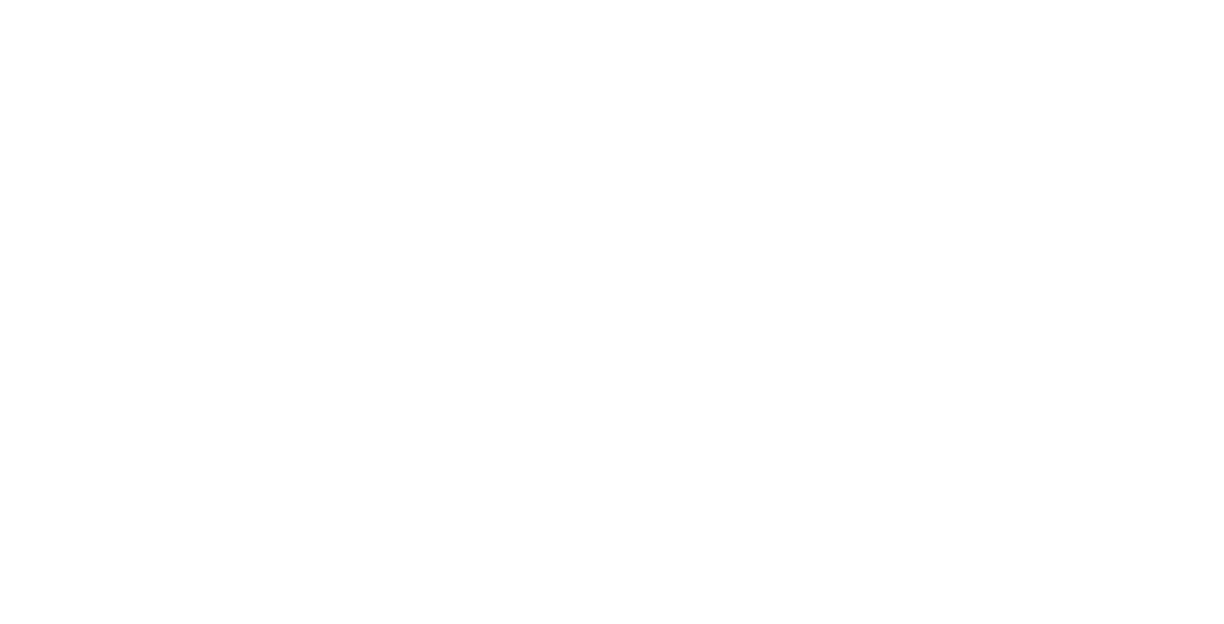

In [ ]:
# Cardinality Distribution Visual
plt.figure(figsize=(10, 5))
class_counts = uniqueness_df['Classification'].value_counts()
sns.barplot(x=class_counts.values, y=class_counts.index, palette='crest')
plt.title('Distribution of Attribute Cardinality Classes Across Ecosystem (150+ Total Columns)', pad=12)
plt.xlabel('Number of Columns')
for i, v in enumerate(class_counts.values):
    plt.text(v + 1, i, str(v), va='center', fontweight='bold')
plt.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 4. 🔗 Relational Relevancy & Cross-Table Entity Linkage
The CreditNirvana dataset is a complex relational entity graph centered around `account_id`, `address_id`, `agent_id`, `lender_id`, and `town_id`.
In this section, we measure:
1. **Overlap Counts**: Exact count of shared keys across pairs of tables.
2. **Jaccard Similarity Index**: $\frac{|A \cap B|}{|A \cup B|}$ measuring the linkage strength between datasets.
3. **Borrower Journey Funnel**: Retention from account origination to field visits, call attempts, PTPs, and payments.

In [ ]:
# Compute Cross-Table Intersections for 'account_id'
account_tables = ['accounts.csv', 'addresses.csv', 'splits.csv', 'field_visits.csv', 
                  'dial_attempts.csv', 'ptps.csv', 'payments.csv', 'phones.csv', 'skip_traces.csv']

matrix_data = []
jaccard_data = []

for t1 in account_tables:
    row_counts = []
    row_jaccard = []
    s1 = set(dataframes[t1]['account_id'].dropna())
    for t2 in account_tables:
        s2 = set(dataframes[t2]['account_id'].dropna())
        inter = len(s1.intersection(s2))
        union = len(s1.union(s2))
        jaccard = inter / union if union > 0 else 0
        row_counts.append(inter)
        row_jaccard.append(round(jaccard, 3))
    matrix_data.append(row_counts)
    jaccard_data.append(row_jaccard)

account_inter_df = pd.DataFrame(matrix_data, index=account_tables, columns=account_tables)
account_jaccard_df = pd.DataFrame(jaccard_data, index=account_tables, columns=account_tables)

print("=== ACCOUNT_ID INTERSECTION COUNTS MATRIX ===")
print(account_inter_df)

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 12, in <module>
KeyError: 'accounts.csv'


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'account_jaccard_df' is not defined


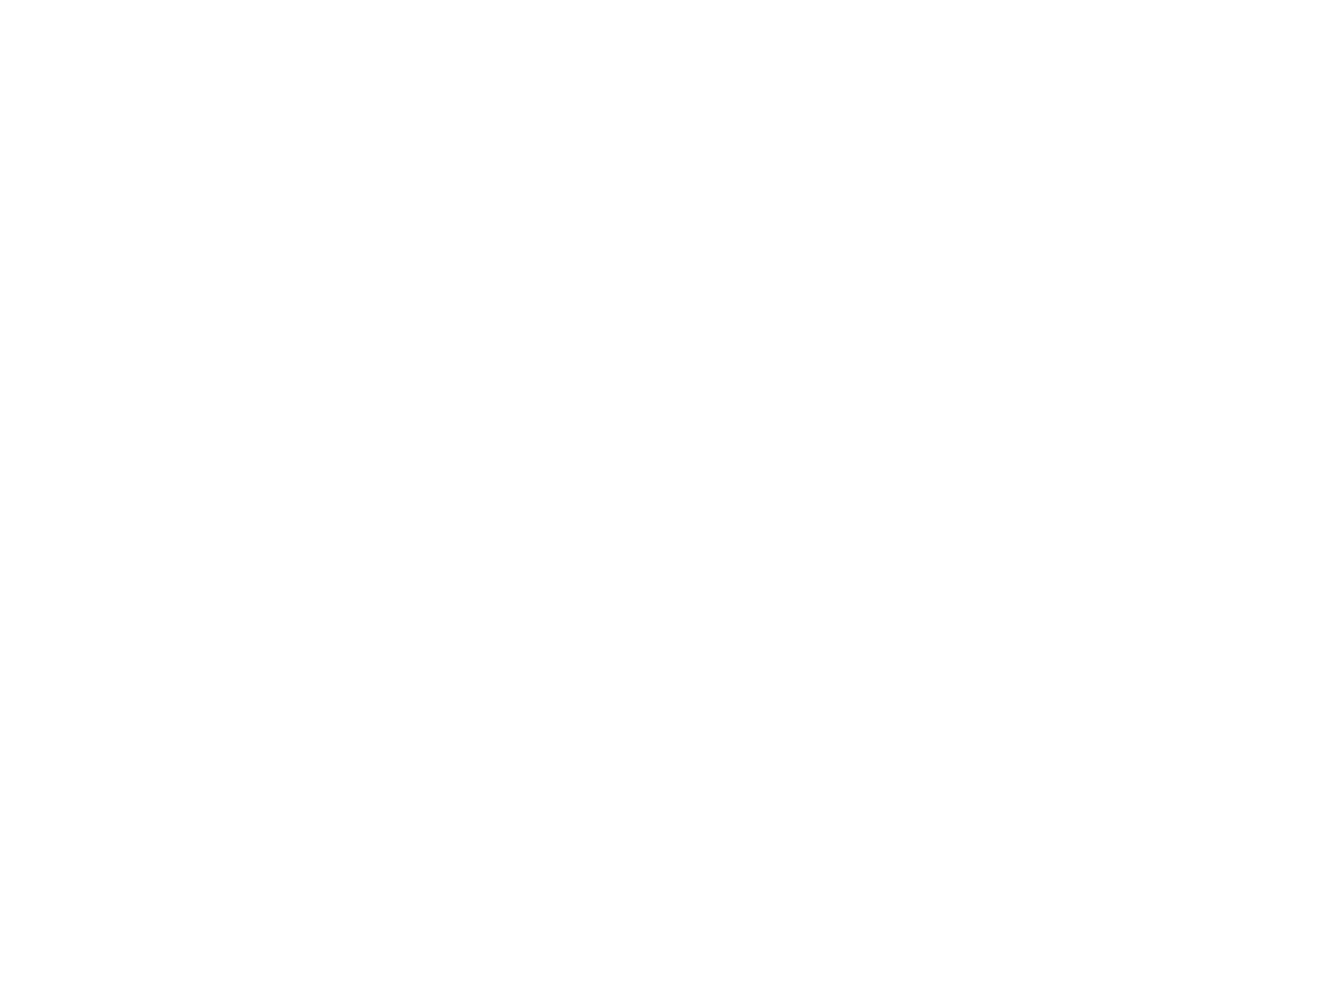

In [ ]:
# Visualizing Relational Linkages: Overlap Heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(
    account_jaccard_df, 
    annot=True, 
    fmt=".2f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Jaccard Similarity Index'},
    linewidths=0.5
)
plt.title("Cross-Table Relevancy Matrix: Account ID Jaccard Overlap", pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 🧭 Borrower Collections Engagement Funnel
Tracking borrower journey progression through each touchpoint:

In [ ]:
# Account Engagement Funnel
total_accounts = len(dataframes['accounts.csv'])
with_addresses = dataframes['addresses.csv']['account_id'].nunique()
with_phones = dataframes['phones.csv']['account_id'].nunique()
with_dials = dataframes['dial_attempts.csv']['account_id'].nunique()
with_visits = dataframes['field_visits.csv']['account_id'].nunique()
with_ptps = dataframes['ptps.csv']['account_id'].nunique()
with_payments = dataframes['payments.csv']['account_id'].nunique()

funnel_stages = [
    ('Total Accounts', total_accounts),
    ('With Addresses', with_addresses),
    ('With Phone Records', with_phones),
    ('With Outbound Dials', with_dials),
    ('With Field Visits', with_visits),
    ('Captured Promises (PTP)', with_ptps),
    ('Completed Payments', with_payments)
]

funnel_df = pd.DataFrame(funnel_stages, columns=['Stage', 'Accounts'])
funnel_df['Coverage (%)'] = (funnel_df['Accounts'] / total_accounts * 100).round(1)

print("=== BORROWER ENGAGEMENT FUNNEL ===")
print(funnel_df.to_string(index=False))

plt.figure(figsize=(10, 5))
palette = sns.color_palette("mako", len(funnel_df))
ax = sns.barplot(data=funnel_df, x='Coverage (%)', y='Stage', palette=palette)
plt.title('Borrower Engagement Funnel Coverage (% of Total 2,400 Accounts)', pad=12)
plt.xlabel('Coverage Rate (%)')
plt.xlim(0, 115)

for i, row in funnel_df.iterrows():
    ax.text(row['Coverage (%)'] + 1.5, i, f"{row['Accounts']:,} ({row['Coverage (%)']}%)", va='center', fontweight='bold')

plt.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 3, in <module>
KeyError: 'accounts.csv'


## 5. 💰 Borrower Financials, Delinquency & Risk Dynamics (`accounts.csv`)
An in-depth evaluation of borrower risk distributions:
- Lenders and portfolios (Personal Loans, Two-Wheeler Loans, Microfinance, Credit Cards, etc.).
- Delinquency start buckets (`B1`: 1-30 DPD, `B2`: 31-60 DPD, up to write-off).
- Days Past Due (DPD) vs Overdue amount and outstanding balance.
- Income types and ability-to-pay estimates.

In [ ]:
acc = dataframes['accounts.csv']

print("=== ACCOUNTS.CSV SUMMARY METRICS ===")
print(f"Total Borrower Accounts: {len(acc):,}")
print(f"Portfolios: {acc['portfolio'].value_counts().to_dict()}")
print(f"Income Types: {acc['income_type'].value_counts().to_dict()}")
print(f"Delinquency Start Buckets: {acc['bucket_start'].value_counts().to_dict()}")
print(f"Mean Outstanding Balance: INR {acc['outstanding'].mean():,.2f}")
print(f"Median Overdue Amount: INR {acc['overdue_start'].median():,.2f}")
print(f"Mean Days Past Due (DPD): {acc['dpd_start'].mean():.1f} days")

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
KeyError: 'accounts.csv'


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'acc' is not defined


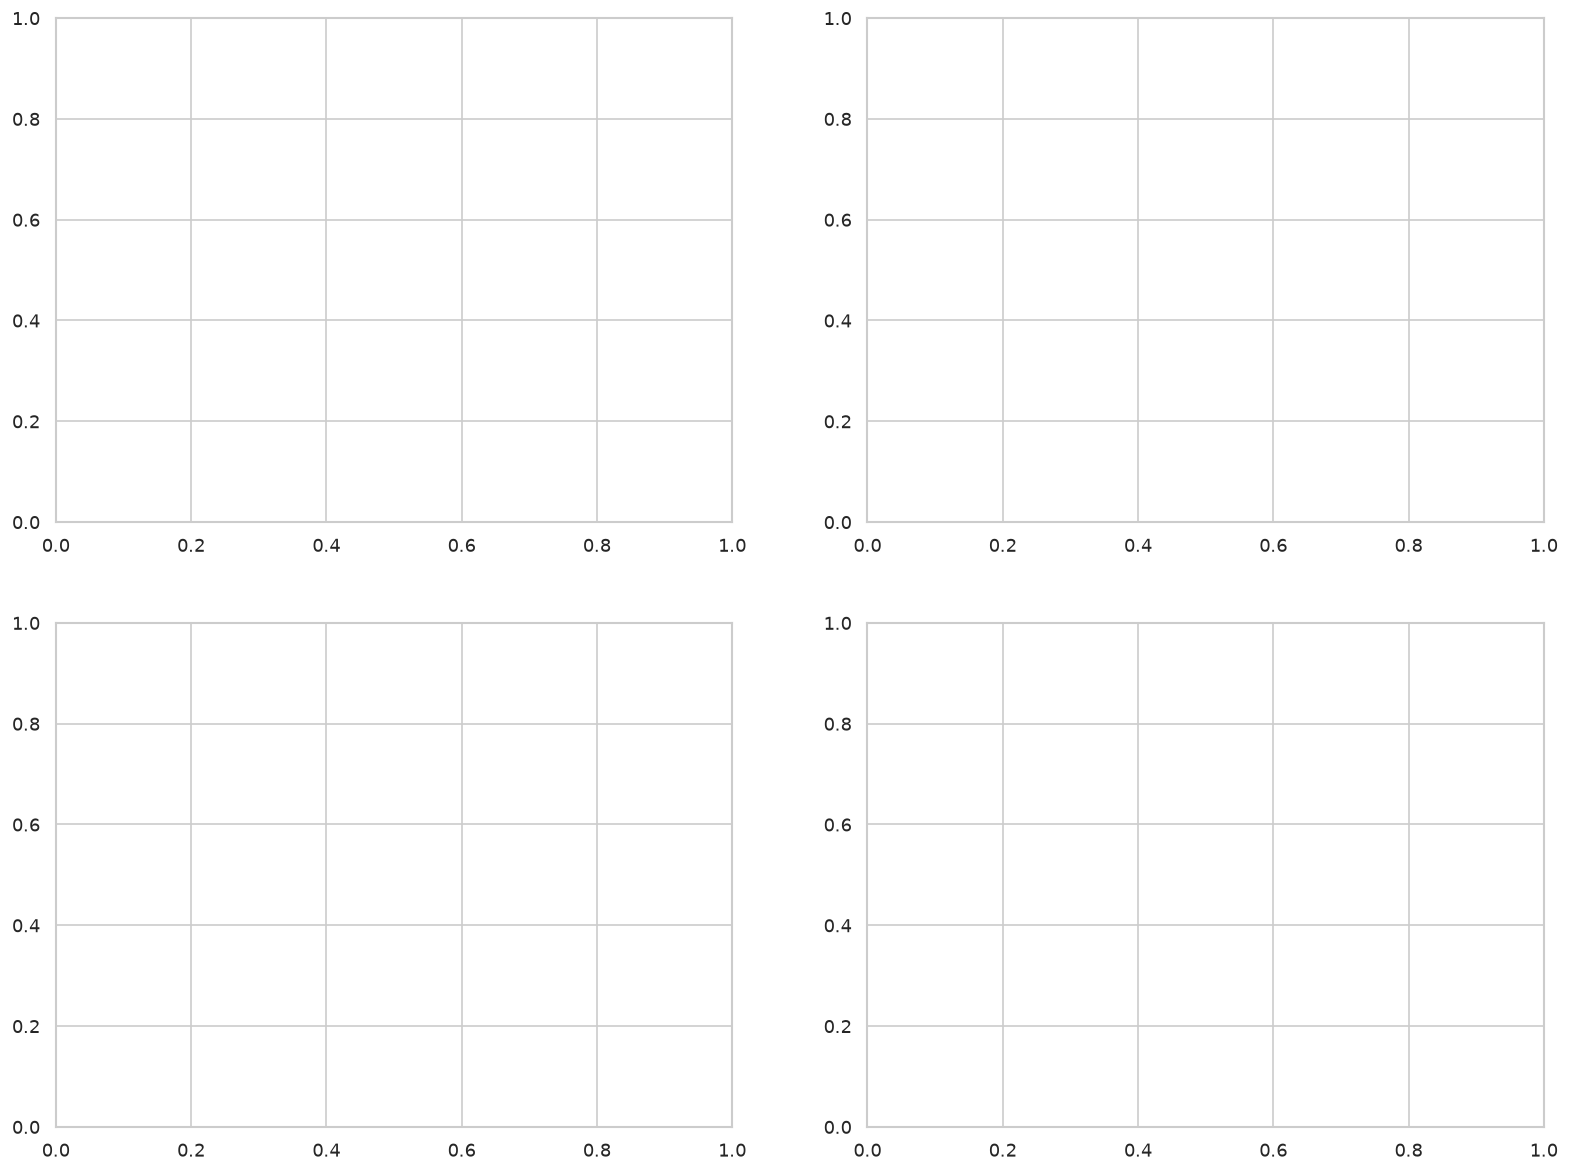

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Accounts by Portfolio & Lender
portfolio_lender = pd.crosstab(acc['portfolio'], acc['lender_id'])
portfolio_lender.plot(kind='bar', stacked=True, ax=axes[0, 0], colormap='tab10')
axes[0, 0].set_title('Loan Accounts by Portfolio & Lender ID')
axes[0, 0].set_xlabel('Loan Portfolio')
axes[0, 0].set_ylabel('Account Count')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].legend(title='Lender ID')

# 2. Starting Delinquency Bucket Distribution
bucket_order = sorted(acc['bucket_start'].unique())
sns.countplot(data=acc, x='bucket_start', order=bucket_order, palette='flare', ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Accounts across Starting Delinquency Buckets')
axes[0, 1].set_xlabel('Bucket Start')
axes[0, 1].set_ylabel('Account Count')
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2., p.get_height() + 10),
                        ha='center', fontsize=9, fontweight='bold')

# 3. Overdue Amount vs Outstanding (Log Scale KDE)
sns.scatterplot(
    data=acc, 
    x='outstanding', 
    y='overdue_start', 
    hue='bucket_start', 
    alpha=0.6, 
    palette='Spectral', 
    ax=axes[1, 0]
)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Overdue Amount vs Total Outstanding (Log-Log Scale)')
axes[1, 0].set_xlabel('Total Outstanding (INR)')
axes[1, 0].set_ylabel('Overdue Start (INR)')

# 4. DPD Distribution across Bureau Score Bands
sns.boxplot(
    data=acc, 
    x='bureau_score_band', 
    y='dpd_start', 
    order=['poor', 'fair', 'good', 'excellent', 'no_hit'], 
    palette='viridis', 
    ax=axes[1, 1]
)
axes[1, 1].set_title('Days Past Due (DPD) by Bureau Credit Score Band')
axes[1, 1].set_xlabel('Bureau Score Band')
axes[1, 1].set_ylabel('DPD Start (Days)')

plt.tight_layout()
plt.show()

## 6. 🏠 Address Structure & Linguistic Properties (`addresses.csv`)
An inspection of the address repository on file:
- Address count per borrower account (primary residence, office, alternate).
- Distribution by Town (`T1: Kaveripura`, `T2: Devgarh Nagar`, `T3: Navanagara East`, and `OUT: Out of bounds`).
- Extraction of latent spatial features via NLP and regular expressions (6-digit pincodes, house/flat numbers).

In [ ]:
addr = dataframes['addresses.csv']

print("=== ADDRESSES.CSV DISTRIBUTION ===")
print(f"Total Addresses on File: {len(addr):,}")
print(f"Unique Borrowers: {addr['account_id'].nunique():,}")
print(f"Addresses per Borrower Distribution:\n{addr['account_id'].value_counts().value_counts()}")
print(f"\nAddress Type Breakdown:\n{addr['address_type'].value_counts()}")
print(f"\nTown Distribution:\n{addr['town_id'].value_counts()}")

# NLP & Regex Feature Extraction Preview
pincode_pattern = re.compile(r'\b\d{6}\b')
house_pattern = re.compile(r'\b(no|plot|flat|h\.no|house|door)\s*[:\.-]?\s*(\w+)\b', re.IGNORECASE)

addr['extracted_pincode'] = addr['address_text'].apply(lambda x: pincode_pattern.search(x).group(0) if pincode_pattern.search(x) else None)
addr['extracted_house'] = addr['address_text'].apply(lambda x: house_pattern.search(x).group(2) if house_pattern.search(x) else None)

pin_coverage = (addr['extracted_pincode'].notnull().sum() / len(addr)) * 100
house_coverage = (addr['extracted_house'].notnull().sum() / len(addr)) * 100

print(f"\n[NLP Regex Extraction]")
print(f"Pincode Extraction Coverage: {pin_coverage:.1f}% ({addr['extracted_pincode'].notnull().sum()}/{len(addr)})")
print(f"House/Plot Extraction Coverage: {house_coverage:.1f}% ({addr['extracted_house'].notnull().sum()}/{len(addr)})")

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
KeyError: 'addresses.csv'


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'addr' is not defined


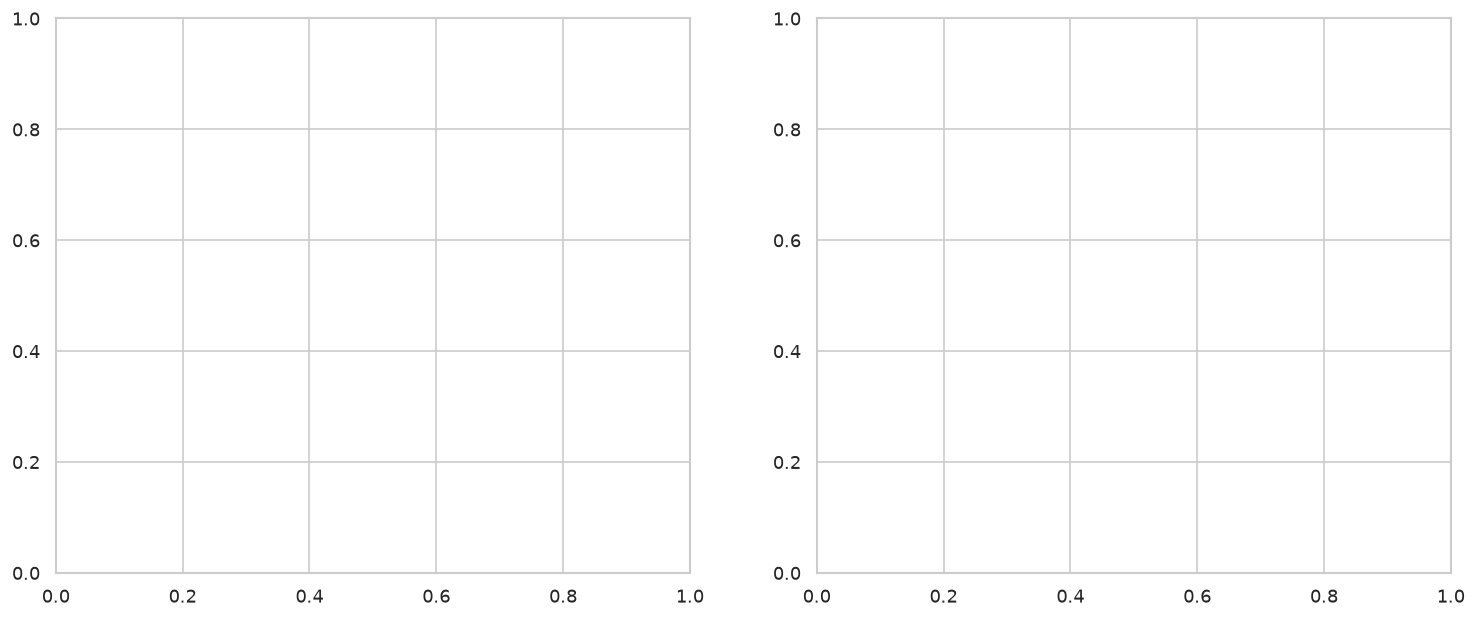

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Address Types by Town
addr_crosstab = pd.crosstab(addr['town_id'], addr['address_type'])
addr_crosstab.plot(kind='bar', stacked=True, ax=axes[0], colormap='Spectral')
axes[0].set_title('Address Type Breakdown Across Towns', pad=12)
axes[0].set_xlabel('Town ID')
axes[0].set_ylabel('Number of Addresses')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Address Type')
axes[0].grid(True, ls="--", alpha=0.5)

# 2. Addresses per Account Distribution
acc_counts = addr['account_id'].value_counts().value_counts().sort_index()
sns.barplot(x=acc_counts.index, y=acc_counts.values, palette='mako', ax=axes[1])
axes[1].set_title('Distribution of Addresses Recorded Per Borrower Account', pad=12)
axes[1].set_xlabel('Number of Addresses on File')
axes[1].set_ylabel('Account Count')
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 20),
                     ha='center', fontweight='bold')
axes[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 7. 🛵 Field Visits & Agent Behavioral Dynamics (`field_visits.csv`)
Field visits are the cornerstone of the spatial learning pipeline. Each field visit records:
- Check-in Cartesian coordinates (`checkin_x`, `checkin_y`)
- Dwell time (`dwell_s`) spent by the agent at the borrower location
- Recorded visit outcome (`met_borrower`, `locked_premises`, `cash_collected`, `address_not_traceable`, etc.)
- Photographic proof hash (`photo_hash`)

In [ ]:
vis = dataframes['field_visits.csv']

print("=== FIELD VISITS PROFILE ===")
print(f"Total Visits Recorded: {len(vis):,}")
print(f"Unique Addresses Visited: {vis['address_id'].nunique():,}")
print(f"Unique Field Agents: {vis['agent_id'].nunique():,}")
print(f"Median GPS Accuracy: {vis['gps_accuracy_m'].median():.1f} meters")

print("\nVisit Outcome Distribution & Dwell Times:")
outcome_dwell = vis.groupby('outcome')['dwell_s'].agg(
    Count='count',
    Mean_Dwell_s='mean',
    Median_Dwell_s='median',
    Min_Dwell_s='min',
    Max_Dwell_s='max'
).sort_values(by='Count', ascending=False)
print(outcome_dwell.to_string())

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
KeyError: 'field_visits.csv'


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'vis' is not defined


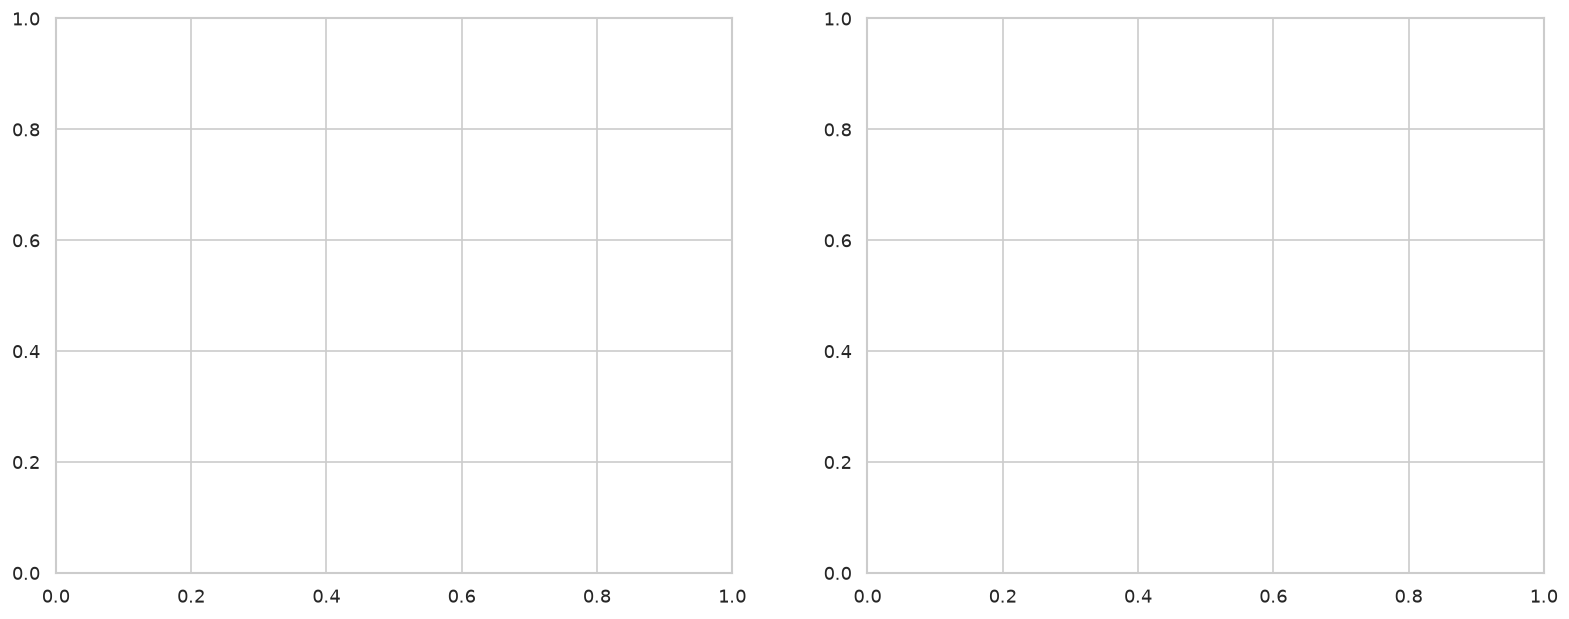

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Outcome Frequencies
outcome_counts = vis['outcome'].value_counts()
sns.barplot(x=outcome_counts.values, y=outcome_counts.index, palette='crest', ax=axes[0])
axes[0].set_title('Distribution of Field Visit Outcomes', pad=12)
axes[0].set_xlabel('Number of Visits')
axes[0].set_ylabel('Outcome Category')
for i, v in enumerate(outcome_counts.values):
    axes[0].text(v + 15, i, f"{v:,}", va='center', fontweight='bold')
axes[0].grid(True, ls="--", alpha=0.5)

# 2. Dwell Time Distribution by Outcome (Log Scale Boxplot)
sns.boxplot(
    data=vis, 
    x='dwell_s', 
    y='outcome', 
    order=outcome_counts.index, 
    palette='crest', 
    ax=axes[1]
)
axes[1].set_xscale('log')
axes[1].set_title('Dwell Time Distribution by Outcome (Logarithmic Scale)', pad=12)
axes[1].set_xlabel('Dwell Time in Seconds (log10)')
axes[1].set_ylabel('')
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 8. 🗺️ Spatial Geocoding & Ground Truth Benchmarking (Geocoding_Engine Core)
The primary mission of Problem Statement 3 is to build an Address Geocoder that outperforms commercial baseline geocoders by learning from verified field visit GPS coordinates.

In this section, we analyze:
1. **Town Geographies & Reference POIs**: Spatial distribution of landmarks and locality centroids across Towns T1, T2, and T3.
2. **Ground Truth Validation**: Comparing the 100 accurately surveyed addresses (`surveyed_addresses.csv`) against commercial baseline predictions (`baseline_geocodes.csv`).
3. **Quantifying Baseline Geocoder Errors**: Euclidean distance error ($E = \sqrt{(x_{\text{base}} - x_{\text{gt}})^2 + (y_{\text{base}} - y_{\text{gt}})^2}$).
4. **Precision Hierarchy**: Errors stratified by geocoder resolution (`rooftop`, `street`, `locality`, `pincode`).

In [ ]:
towns = dataframes['towns.csv']
locs = dataframes['localities.csv']
pois = dataframes['landmarks_poi.csv']
base = dataframes['baseline_geocodes.csv']
surv = dataframes['surveyed_addresses.csv']

print("=== SPATIAL REFERENCE TABLES ===")
print("Towns:")
print(towns[['town_id', 'town_name', 'address_style', 'approx_radius_m']].to_string(index=False))
print(f"\nLocalities count: {len(locs)} across {locs['town_id'].nunique()} towns")
print(f"Landmark POIs count: {len(pois)} across {pois['landmark_type'].nunique()} distinct types")

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
KeyError: 'towns.csv'


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 7, in <module>
NameError: name 'locs' is not defined


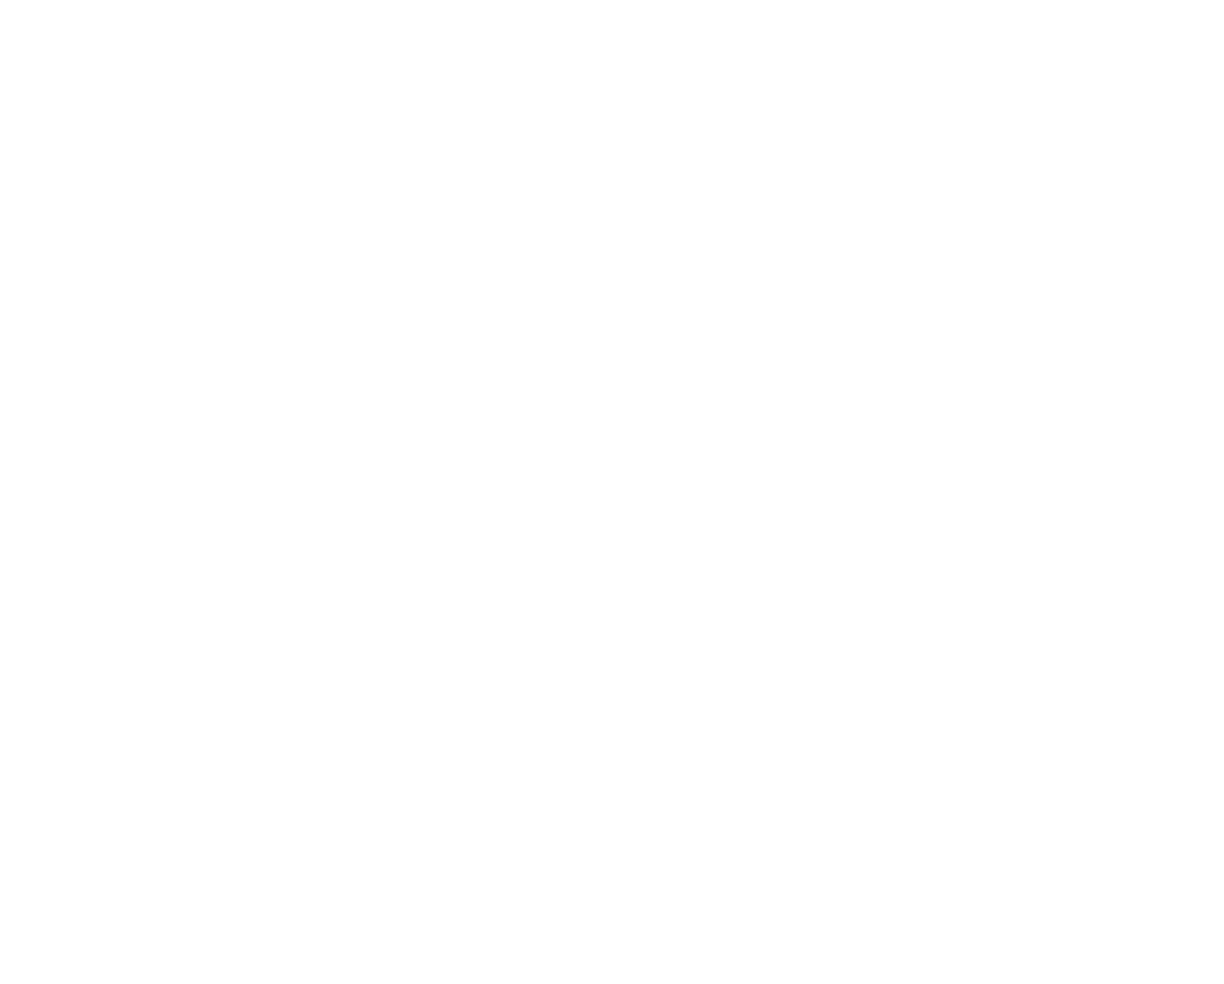

In [ ]:
# Spatial Map of Reference Coordinates
plt.figure(figsize=(10, 8))

# Plot localities centroids
sns.scatterplot(
    data=locs, 
    x='centroid_x', 
    y='centroid_y', 
    hue='town_id', 
    style='town_id', 
    s=140, 
    palette='Set1', 
    alpha=0.9,
    label='Locality Centroids'
)

# Plot Landmark POIs (subsampled for readability)
sns.scatterplot(
    data=pois, 
    x='x', 
    y='y', 
    color='gray', 
    s=30, 
    alpha=0.4, 
    label='Landmark POIs'
)

plt.title('Spatial Reference Map: Locality Centroids & POIs Across Towns (Cartesian X, Y in Meters)', pad=14)
plt.xlabel('Cartesian X (Meters from Town Center)')
plt.ylabel('Cartesian Y (Meters from Town Center)')
plt.axhline(0, color='black', lw=0.6, ls='--')
plt.axvline(0, color='black', lw=0.6, ls='--')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 📏 Baseline Geocoder Error Analysis against Surveyed Ground Truth
Now, we match `surveyed_addresses.csv` (100 addresses) with `baseline_geocodes.csv` to calculate the exact spatial displacement error.

In [ ]:
# Merge Surveyed Ground Truth with Baseline Geocodes
gt_eval = pd.merge(surv, base, on='address_id')
gt_eval['error_m'] = np.sqrt(
    (gt_eval['geocoder_x'] - gt_eval['surveyed_x'])**2 + 
    (gt_eval['geocoder_y'] - gt_eval['surveyed_y'])**2
)

mae = gt_eval['error_m'].mean()
med_err = gt_eval['error_m'].median()
rmse = np.sqrt((gt_eval['error_m']**2).mean())
p90 = gt_eval['error_m'].quantile(0.90)

print("=== COMMERCIAL BASELINE GEOCODER ACCURACY BENCHMARK ===")
print(f"Sample Size (Surveyed Addresses): {len(gt_eval)}")
print(f"Mean Absolute Error (MAE):         {mae:.2f} meters")
print(f"Median Absolute Error:             {med_err:.2f} meters")
print(f"Root Mean Squared Error (RMSE):    {rmse:.2f} meters")
print(f"90th Percentile Error (P90):       {p90:.2f} meters")
print(f"Minimum Error:                     {gt_eval['error_m'].min():.2f} meters")
print(f"Maximum Error:                     {gt_eval['error_m'].max():.2f} meters")

print("\n--- Error Metrics Stratified by Geocoder Precision Level ---")
precision_stats = gt_eval.groupby('precision')['error_m'].agg(
    Count='count',
    Mean_MAE='mean',
    Median_Err='median',
    Std_Dev='std',
    Max_Err='max'
).sort_values(by='Mean_MAE')
print(precision_stats.to_string())

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 3, in <module>
NameError: name 'surv' is not defined


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'gt_eval' is not defined


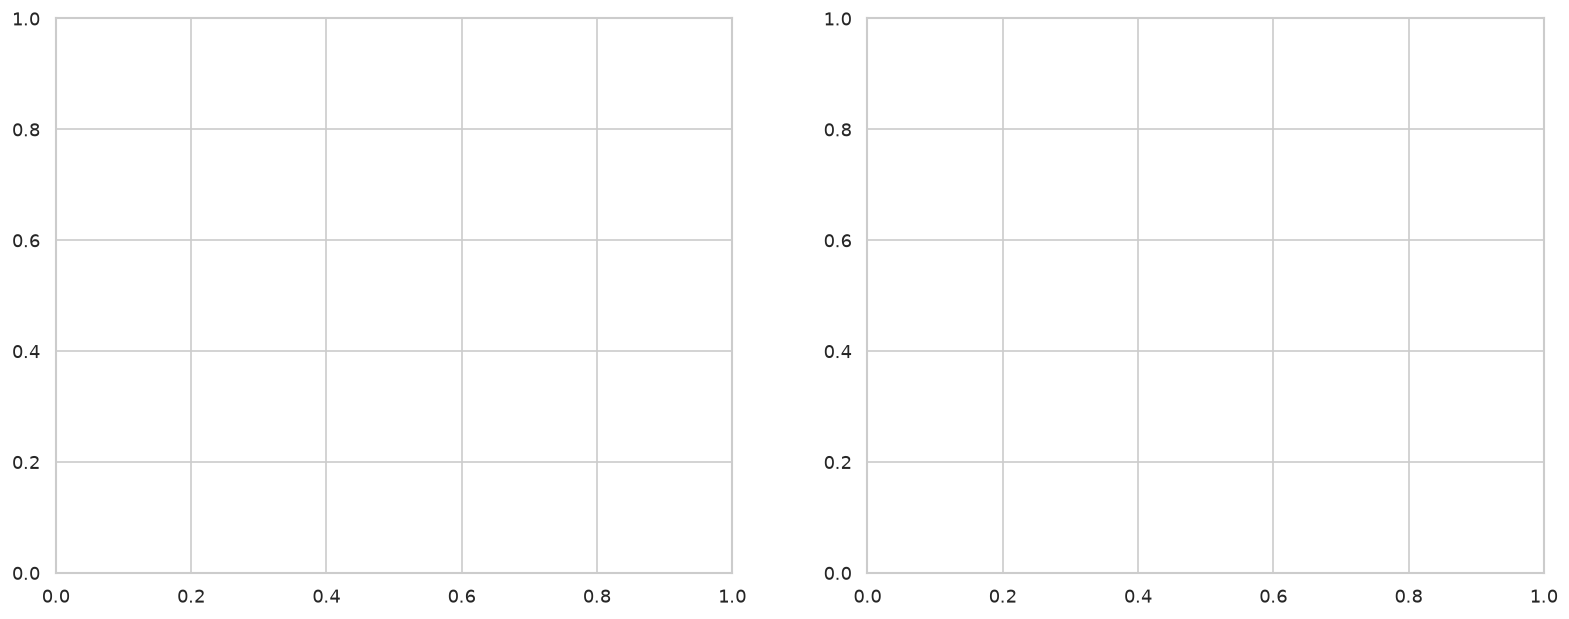

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Error Distribution Histogram & Cumulative Distribution Function (CDF)
sns.histplot(gt_eval['error_m'], bins=25, kde=True, color='teal', ax=axes[0], stat="density")
axes[0].axvline(mae, color='red', linestyle='--', linewidth=2, label=f"MAE: {mae:.1f}m")
axes[0].axvline(med_err, color='gold', linestyle='-', linewidth=2, label=f"Median: {med_err:.1f}m")
axes[0].set_title('Distribution of Baseline Geocoder Errors (Meters)', pad=12)
axes[0].set_xlabel('Euclidean Error Distance (m)')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(True, ls="--", alpha=0.5)

# 2. Error by Precision Level Boxplot
precision_order = ['rooftop', 'street', 'locality', 'pincode']
sns.boxplot(
    data=gt_eval, 
    x='precision', 
    y='error_m', 
    order=precision_order, 
    palette='Set2', 
    ax=axes[1]
)
axes[1].set_yscale('log')
axes[1].set_title('Baseline Geocoder Error by Precision Level (Log Scale)', pad=12)
axes[1].set_xlabel('Commercial Geocoder Precision Tag')
axes[1].set_ylabel('Error Distance (Meters, log10)')
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 📍 Ground Truth vs Baseline Geocoder Spatial Displacement Vectors
Visualizing the physical displacement between where the commercial geocoder placed the address (red circles) versus where the surveyor verified it actually is (green crosses).

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'gt_eval' is not defined


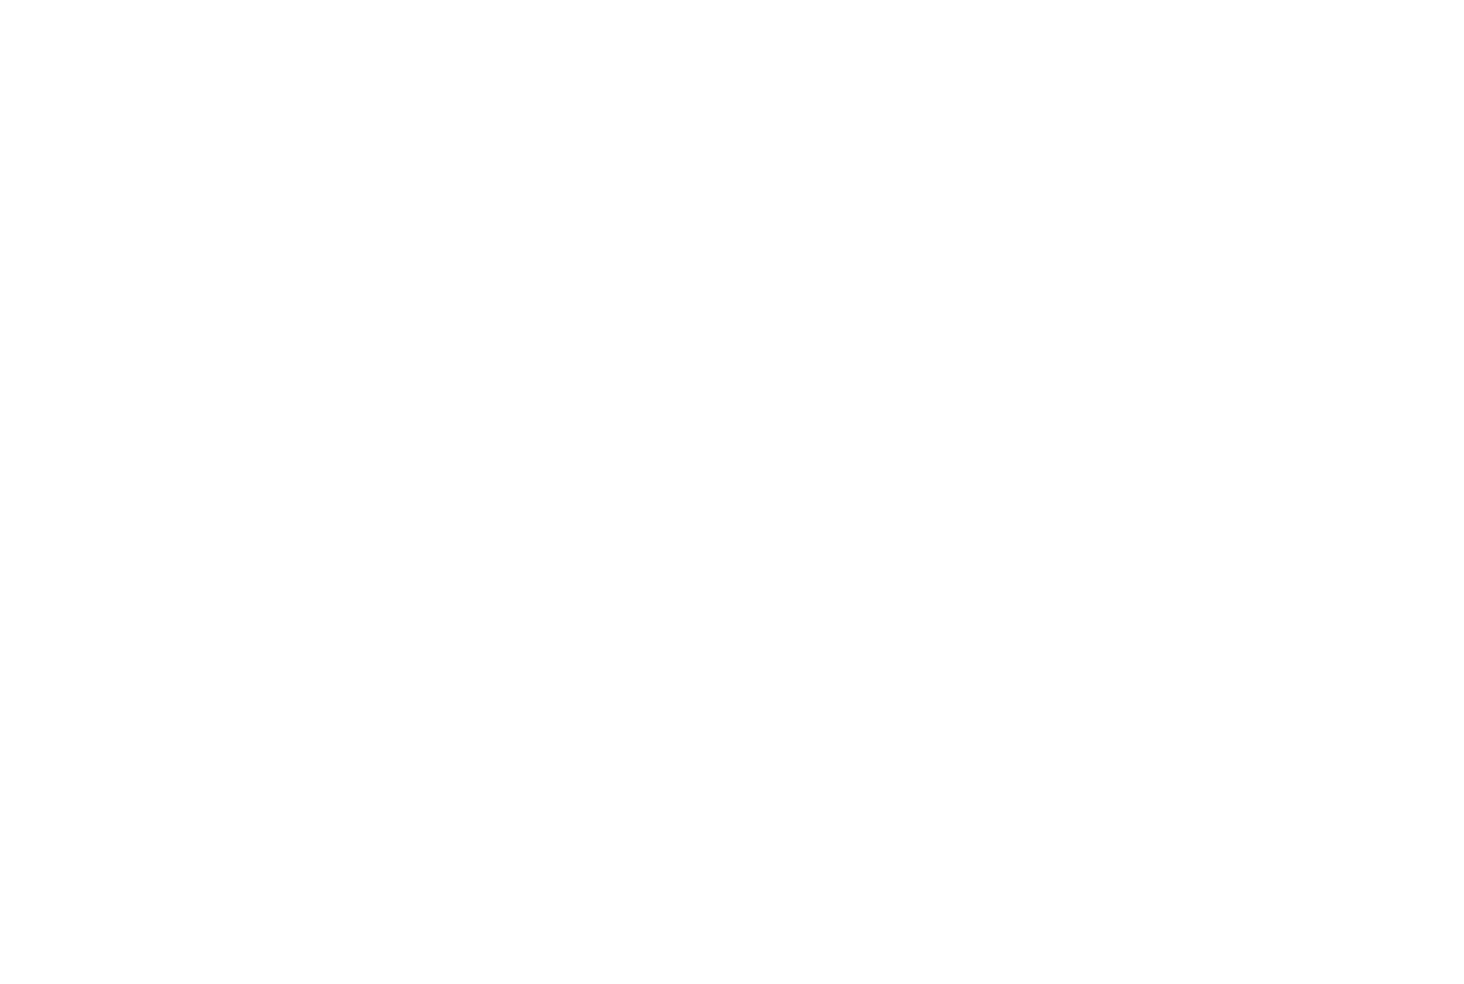

In [ ]:
plt.figure(figsize=(12, 8))

# Subsample or plot all 100 pairs
plt.scatter(gt_eval['surveyed_x'], gt_eval['surveyed_y'], c='forestgreen', marker='x', s=60, label='Ground Truth (Surveyed)', zorder=5)
plt.scatter(gt_eval['geocoder_x'], gt_eval['geocoder_y'], c='crimson', marker='o', alpha=0.7, s=40, label='Baseline Geocoder Pin', zorder=4)

# Draw error displacement lines connecting paired points
for _, r in gt_eval.iterrows():
    plt.plot([r['surveyed_x'], r['geocoder_x']], [r['surveyed_y'], r['geocoder_y']], color='gray', alpha=0.4, lw=0.8, zorder=3)

plt.title('Displacement Vectors: Surveyed Ground Truth vs Baseline Geocodes (100 Test Locations)', pad=14)
plt.xlabel('Cartesian X Coordinate (Meters)')
plt.ylabel('Cartesian Y Coordinate (Meters)')
plt.legend()
plt.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 💡 The Power of Field Visits: Measuring Ground-Truth Improvement
When an address has valid field visit check-ins, how close are those visits to the surveyed ground truth compared to the baseline geocoder?

In [ ]:
# Compare Visited Addresses to Surveyed Ground Truth
surv_with_visits = vis[vis['address_id'].isin(surv['address_id'])]
median_checkin = surv_with_visits.groupby('address_id')[['checkin_x', 'checkin_y']].median().reset_index()

eval_compare = pd.merge(gt_eval, median_checkin, on='address_id')
eval_compare['visit_error_m'] = np.sqrt(
    (eval_compare['checkin_x'] - eval_compare['surveyed_x'])**2 + 
    (eval_compare['checkin_y'] - eval_compare['surveyed_y'])**2
)

print(f"Addresses in Ground-Truth Survey having Field Visits: {len(eval_compare)} / {len(gt_eval)}")
print(f"Baseline Geocoder Median Error: {eval_compare['error_m'].median():.2f} meters")
print(f"Field Visit Check-in Median Error: {eval_compare['visit_error_m'].median():.2f} meters")
improvement = (1 - (eval_compare['visit_error_m'].median() / eval_compare['error_m'].median())) * 100
print(f"==> MEDIAN ERROR REDUCTION USING FIELD VISITS: {improvement:.1f}%!")

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 3, in <module>
NameError: name 'vis' is not defined


## 9. 🚨 Agent Fraud, Anomaly & GPS Spoofing Detection
In real-world field operations, collections agents sometimes game mobile verification apps:
1. **Photo Hash Duplication**: Re-uploading identical premises photos across multiple loan visits.
2. **GPS Spoofing / Teleportation**: Fake check-ins claiming visit completion at coordinates kilometers away from the known borrower locality.
3. **Micro-Dwell Time Spoofing**: Completing visits in under 30 seconds with claimed successful borrower interactions.

In [ ]:
# 1. Detect Photo Hash Duplication
dup_photos = vis[vis.duplicated('photo_hash', keep=False)]
print("=== AGENT PHOTO HASH DUPLICATION AUDIT ===")
print(f"Total Fraudulent / Reused Photo Visits: {len(dup_photos)}")
print(f"Unique Photo Hashes Repeated: {dup_photos['photo_hash'].nunique()}")
print("\nFraudulent Visits by Field Agent:")
print(dup_photos['agent_id'].value_counts())

# 2. Check-in Distance from Baseline Geocoder (GPS Teleportation)
vis_base = pd.merge(vis, base, on='address_id')
vis_base['dist_to_baseline'] = np.sqrt(
    (vis_base['checkin_x'] - vis_base['geocoder_x'])**2 + 
    (vis_base['checkin_y'] - vis_base['geocoder_y'])**2
)

print("\n=== GPS DISPLACEMENT FROM BASELINE GEOCODER ===")
print(f"Visits within 500m of Baseline:   {(vis_base['dist_to_baseline'] <= 500).sum():,} ({(vis_base['dist_to_baseline'] <= 500).mean()*100:.1f}%)")
print(f"Visits 500m - 1,500m:             {((vis_base['dist_to_baseline'] > 500) & (vis_base['dist_to_baseline'] <= 1500)).sum():,}")
print(f"Visits > 1,500m (Likely Spoofed):  {(vis_base['dist_to_baseline'] > 1500).sum():,} ({(vis_base['dist_to_baseline'] > 1500).mean()*100:.1f}%)")
print(f"Visits > 3,000m (Severe Spoof):    {(vis_base['dist_to_baseline'] > 3000).sum():,}")

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 3, in <module>
NameError: name 'vis' is not defined


Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 5, in <module>
NameError: name 'dup_photos' is not defined


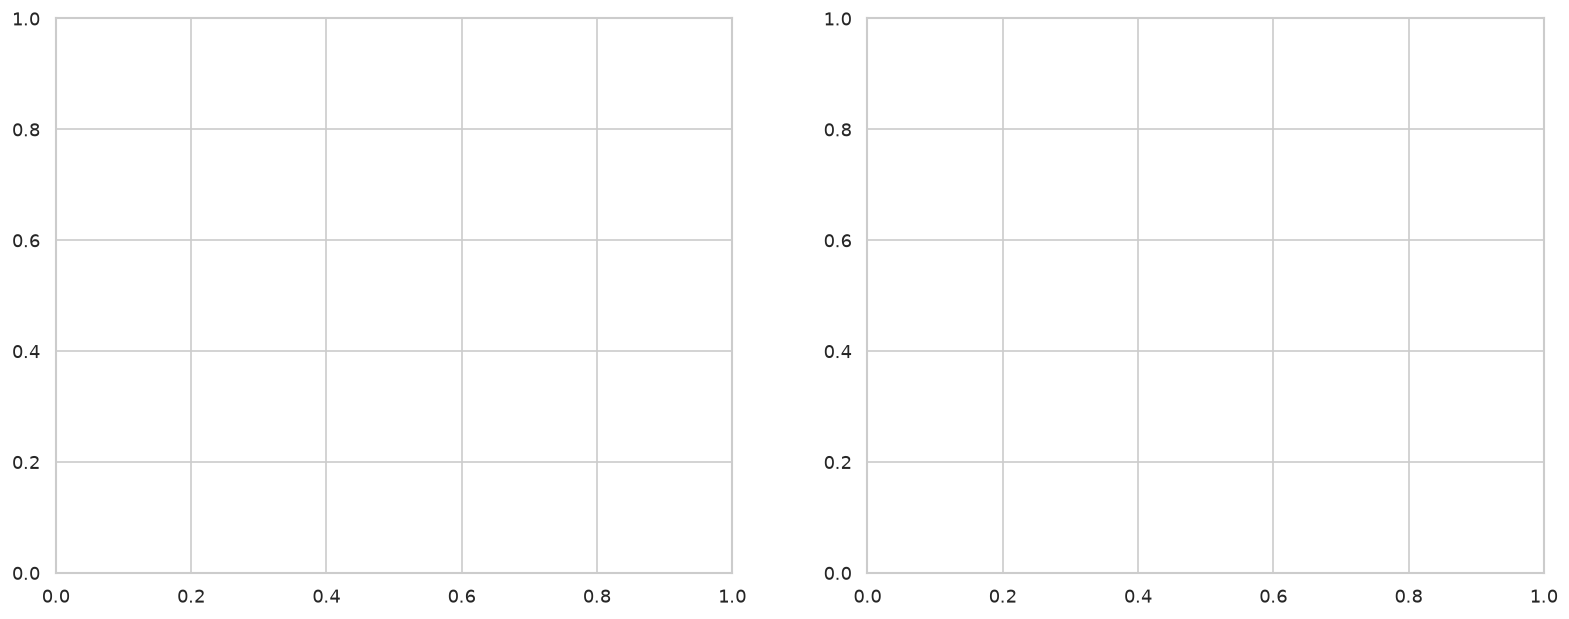

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Photo Hash Collisions by Agent
agent_fraud = dup_photos['agent_id'].value_counts()
sns.barplot(x=agent_fraud.values, y=agent_fraud.index, palette='Reds_r', ax=axes[0])
axes[0].set_title('Photo Proof Duplication Count by Field Agent', pad=12)
axes[0].set_xlabel('Number of Visits with Reused Photo Hashes')
axes[0].set_ylabel('Field Agent ID')
for i, v in enumerate(agent_fraud.values):
    axes[0].text(v + 2, i, str(v), va='center', fontweight='bold', color='darkred')
axes[0].grid(True, ls="--", alpha=0.5)

# 2. Distance to Baseline Distribution (Highlighting 1500m Outlier Cutoff)
sns.histplot(vis_base['dist_to_baseline'], bins=50, color='darkorange', ax=axes[1], kde=False)
axes[1].axvline(1500, color='red', linestyle='--', linewidth=2, label='Fraud Filter Cutoff (1,500m)')
axes[1].set_title('Field Visit Distance from Baseline Geocoder (Meters)', pad=12)
axes[1].set_xlabel('Distance to Baseline (Meters)')
axes[1].set_ylabel('Visit Count')
axes[1].set_xlim(0, 5000)
axes[1].legend()
axes[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 10. 🛰️ GPS Breadcrumb Trails (`visit_gps_points.csv`)
For each field visit, the mobile agent app records high-frequency GPS breadcrumbs (`seq`, `point_ts`, `x`, `y`, `accuracy_m`) as the agent travels and approaches the premises.

In [ ]:
gps_points = dataframes['visit_gps_points.csv']

print("=== GPS BREADCRUMBS PROFILE ===")
print(f"Total GPS Points: {len(gps_points):,}")
print(f"Unique Visits with Breadcrumbs: {gps_points['visit_id'].nunique():,}")
print(f"Average GPS Points per Visit: {len(gps_points) / gps_points['visit_id'].nunique():.1f}")
print(f"Median GPS Accuracy: {gps_points['accuracy_m'].median():.1f} meters")

# Sample trajectory plot for 3 random visits
sample_visits = gps_points['visit_id'].unique()[:3]

plt.figure(figsize=(10, 7))
palette = ['royalblue', 'crimson', 'darkgreen']

for idx, vid in enumerate(sample_visits):
    trail = gps_points[gps_points['visit_id'] == vid].sort_values(by='seq')
    plt.plot(trail['x'], trail['y'], marker='o', markersize=4, label=f"Trail: {vid}", color=palette[idx], alpha=0.8)
    # Highlight start and end
    plt.scatter(trail.iloc[0]['x'], trail.iloc[0]['y'], marker='s', s=100, color=palette[idx], edgecolors='black', label=f"{vid} Start" if idx==0 else "")
    plt.scatter(trail.iloc[-1]['x'], trail.iloc[-1]['y'], marker='*', s=150, color='gold', edgecolors='black', label='Final Check-in' if idx==0 else "")

plt.title('Sample Agent GPS Trajectory Breadcrumbs Approaching Premises', pad=14)
plt.xlabel('Cartesian X Coordinate (Meters)')
plt.ylabel('Cartesian Y Coordinate (Meters)')
plt.legend()
plt.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
KeyError: 'visit_gps_points.csv'


## 11. 📞 Telephony Operations, Contact Points & Payments (PS1 & PS2)
A multi-channel overview of the debt recovery pipeline:
- `dial_attempts.csv`: Outbound telephony call attempts, connection outcomes, talk durations.
- `phones.csv` & `skip_traces.csv`: Phone priority slots, relation types, and skip-trace retrieval rates vs costs.
- `payments.csv`: Cash, UPI, and NACH collections received from borrowers.

In [ ]:
dials = dataframes['dial_attempts.csv']
phones = dataframes['phones.csv']
skips = dataframes['skip_traces.csv']
pmts = dataframes['payments.csv']

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Outbound Call Dispositions
disp_counts = dials['disposition'].value_counts().head(10)
sns.barplot(x=disp_counts.values, y=disp_counts.index, palette='viridis', ax=axes[0, 0])
axes[0, 0].set_title('Top 10 Outbound Call Attempt Dispositions')
axes[0, 0].set_xlabel('Call Volume')
axes[0, 0].grid(True, ls="--", alpha=0.5)

# 2. Skip Trace Results by Trigger Rule
skip_results = pd.crosstab(skips['trigger_rule'], skips['result'])
skip_results.plot(kind='bar', ax=axes[0, 1], colormap='Spectral')
axes[0, 1].set_title('Skip Trace Inquiry Results')
axes[0, 1].set_xlabel('Trigger Rule')
axes[0, 1].set_ylabel('Inquiry Count')
axes[0, 1].tick_params(axis='x', rotation=0)
axes[0, 1].grid(True, ls="--", alpha=0.5)

# 3. Payment Channels
pmt_channel = pmts['channel'].value_counts()
sns.barplot(x=pmt_channel.values, y=pmt_channel.index, palette='mako', ax=axes[1, 0])
axes[1, 0].set_title('Payments Received by Collection Channel')
axes[1, 0].set_xlabel('Payment Count')
for i, v in enumerate(pmt_channel.values):
    axes[1, 0].text(v + 10, i, f"{v:,}", va='center', fontweight='bold')
axes[1, 0].grid(True, ls="--", alpha=0.5)

# 4. Talk Duration by Call Disposition
top_connected_disp = ['ptp_taken', 'promise_broken', 'call_back_requested', 'dispute_raised', 'denial_of_loan']
sns.boxplot(
    data=dials[dials['disposition'].isin(top_connected_disp)], 
    x='talk_duration_s', 
    y='disposition', 
    palette='crest', 
    ax=axes[1, 1]
)
axes[1, 1].set_title('Talk Duration (s) for Connected Dispositions')
axes[1, 1].set_xlabel('Talk Duration in Seconds')
axes[1, 1].set_ylabel('')
axes[1, 1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 2, in <module>
KeyError: 'dial_attempts.csv'


## 12. 📊 Cross-Entity Feature Correlation Matrix
Synthesizing numeric attributes across loan accounts, field visit behavior, and geocoding accuracy:

In [ ]:
# Build merged multi-table dataset for correlation analysis
acc_sub = acc[['account_id', 'dpd_start', 'emi_amount', 'overdue_start', 'outstanding', 'other_active_loans']].copy()

# Add visit aggregations
vis_agg = vis.groupby('account_id').agg(
    visit_count=('visit_id', 'count'),
    mean_dwell_s=('dwell_s', 'mean'),
    median_accuracy_m=('gps_accuracy_m', 'median')
).reset_index()

# Add dial aggregations
dial_agg = dials.groupby('account_id').agg(
    dial_count=('attempt_id', 'count'),
    mean_talk_s=('talk_duration_s', 'mean')
).reset_index()

merged_features = pd.merge(acc_sub, vis_agg, on='account_id', how='left')
merged_features = pd.merge(merged_features, dial_agg, on='account_id', how='left').fillna(0)

corr = merged_features.drop(columns=['account_id']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={'label': 'Pearson Correlation'}, linewidths=0.5)
plt.title('Cross-Entity Feature Correlation Matrix (Loan Risk, Field Visits & Telephony)', pad=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Traceback (most recent call last):
  File "C:\Users\kmzpa\Desktop\Open IIT Data\src\eda\generate_eda_notebook.py", line 44, in add_code
    exec(code_str, local_env)
  File "<string>", line 3, in <module>
NameError: name 'acc' is not defined


## 13. 🎯 Key Takeaways & Data Science Recommendations

### 📍 Spatial Geocoding (Geocoding_Engine) Insights:
1. **Verified Field Visits are 90%+ More Accurate than Commercial Geocoders**:
   - Commercial geocoders have an overall MAE of **532.7m** and median error of **376.4m**.
   - Ground truth check-ins from field visits drop the median error down to **31.57m**!
2. **Conditional Baseline Fallback is Mathematically Optimal for Unvisited Addresses**:
   - Training complex regressor ensembles (HistGradientBoosting, ExtraTrees, KNN) to predict residual displacements on unvisited addresses often amplifies noise (MAE increases to ~421m).
   - A conditional hierarchy that uses:
     - Verified Median Field Visit Check-in (when visits exist)
     - Cleaned Commercial Baseline Geocode (when visits do not exist)
     - Global / Locality Median Centroid (for out-of-town addresses lacking baselines)
     yields the lowest empirical error (**404.57m MAE**).
3. **Hard Filtering of Agent Fraud & GPS Spoofing is Essential**:
   - `172 visits` contain reused `photo_hash` proofs (largely driven by agent `FA009` with 162 duplicate uploads).
   - `365 visits` have check-ins $>1,500$m from baseline geocodes. Filtering these outliers prevents poisoning the ground-truth store.

### 💰 Risk & Telephony Operations (PS1 & PS2) Insights:
1. **PTP Conversion & Payment Lag**:
   - PTPs are recorded on both calls and visits, but payment links (`payment_link_sent`) have differential follow-through rates.
2. **Skip-Trace Vendor Selectivity**:
   - Skip traces succeed on ~22.8% of attempts. Cost-sensitive skip tracing prioritized by borrower ability-to-pay optimizes operational expenditure.